# Unemployment Analysis with Python
## Understanding COVID-19's Impact on Employment in India

**Author:** Eng. Reem Osama  
**Track:** Data Science  
**Task:** Task 2 - Unemployment Analysis  
**Organization:** Oasis Infobyte

---

## Project Objective
This notebook performs an exploratory data analysis (EDA) on unemployment data from India, with a particular focus on:
- Regional unemployment trends
- Temporal patterns across different time periods
- The impact of COVID-19 on unemployment rates
- Comparative analysis between pre-COVID and post-COVID periods

---

## Step 1: Import Required Libraries

In [1]:
# Data manipulation and analysis
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Date and time handling
from datetime import datetime
import warnings

# Configure visualization settings
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette('husl')
warnings.filterwarnings('ignore')

# Set display options for better readability
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:.2f}'.format)

print("All libraries imported successfully!")

All libraries imported successfully!


## Step 2: Load and Explore the Dataset

**Dataset Information:**
- Source: Kaggle - "Unemployment in India"


In [2]:

df = pd.read_csv('Unemployment_in_India.csv')

print("Dataset Shape:", df.shape)
print("\n" + "="*60)
print("First 5 rows of the dataset:")
print("="*60)
df.head()

Dataset Shape: (768, 7)

First 5 rows of the dataset:


,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,31-05-2019,Monthly,3.65,11999139.00,43.24,Rural
1,Andhra Pradesh,30-06-2019,Monthly,3.05,11755881.00,42.05,Rural
2,Andhra Pradesh,31-07-2019,Monthly,3.75,12086707.00,43.50,Rural
3,Andhra Pradesh,31-08-2019,Monthly,3.32,12285693.00,43.97,Rural
4,Andhra Pradesh,30-09-2019,Monthly,5.17,12256762.00,44.68,Rural


In [3]:
# dataset information
print("Dataset Information:")
print("="*60)
df.info()
print("\n" + "="*60)
print("Column Names:")
print(df.columns.tolist())

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 7 columns):
 #   Column                                    Non-Null Count  Dtype  
---  ------                                    --------------  -----  
 0   Region                                    740 non-null    str    
 1    Date                                     740 non-null    str    
 2    Frequency                                740 non-null    str    
 3    Estimated Unemployment Rate (%)          740 non-null    float64
 4    Estimated Employed                       740 non-null    float64
 5    Estimated Labour Participation Rate (%)  740 non-null    float64
 6   Area                                      740 non-null    str    
dtypes: float64(3), str(4)
memory usage: 42.1 KB

Column Names:
['Region', ' Date', ' Frequency', ' Estimated Unemployment Rate (%)', ' Estimated Employed', ' Estimated Labour Participation Rate (%)', 'Area']


In [4]:

print("Statistical Summary:")
print("="*60)
df.describe()

Statistical Summary:


,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%)
count,740.00,740.00,740.00
mean,11.79,7204460.03,42.63
std,10.72,8087988.43,8.11
min,0.00,49420.00,13.33
25%,4.66,1190404.50,38.06
50%,8.35,4744178.50,41.16
75%,15.89,11275489.50,45.51
max,76.74,45777509.00,72.57


## Step 3: Data Cleaning and Preprocessing

In this section, we will:
1. Check for missing values
2. Handle null values appropriately
3. Standardize column names
4. Convert data types (especially dates)
5. Remove any duplicates

In [5]:

print("Missing Values Analysis:")
print("="*60)
missing_data = df.isnull().sum()
missing_percent = (df.isnull().sum() / len(df)) * 100
missing_df = pd.DataFrame({
    'Missing Count': missing_data,
    'Percentage': missing_percent
})
print(missing_df[missing_df['Missing Count'] > 0])

if missing_df['Missing Count'].sum() == 0:
    print("\nNo missing values found!")
else:
    print(f"\nTotal missing values: {missing_df['Missing Count'].sum()}")

Missing Values Analysis:
                                          Missing Count  Percentage
Region                                               28        3.65
 Date                                                28        3.65
 Frequency                                           28        3.65
 Estimated Unemployment Rate (%)                     28        3.65
 Estimated Employed                                  28        3.65
 Estimated Labour Participation Rate (%)             28        3.65
Area                                                 28        3.65

Total missing values: 196


In [6]:

df.columns = df.columns.str.strip().str.replace(' ', '_')
print("Column names standardized:")
print(df.columns.tolist())

Column names standardized:
['Region', 'Date', 'Frequency', 'Estimated_Unemployment_Rate_(%)', 'Estimated_Employed', 'Estimated_Labour_Participation_Rate_(%)', 'Area']


In [7]:
# Handle missing values if any exist

if df.isnull().sum().sum() > 0:
    initial_rows = len(df)
    df = df.dropna()
    dropped_rows = initial_rows - len(df)
    print(f"Dropped {dropped_rows} rows with missing values")
    print(f"Clean dataset size: {len(df)} rows")
else:
    print("No missing values to handle")

Dropped 28 rows with missing values
Clean dataset size: 740 rows


In [8]:
# Convert date column to datetime format
date_columns = [col for col in df.columns if 'date' in col.lower()]

if date_columns:
    date_col = date_columns[0]
    df[date_col] = pd.to_datetime(df[date_col], errors='coerce')
    print(f"Date column '{date_col}' converted to datetime")
    
    # Extract additional date features
    df['Year'] = df[date_col].dt.year
    df['Month'] = df[date_col].dt.month
    df['Month_Name'] = df[date_col].dt.strftime('%B')
    df['Quarter'] = df[date_col].dt.quarter
    print("Date features extracted: Year, Month, Month_Name, Quarter")
else:
    print("No date column found. Please verify your dataset.")

Date column 'Date' converted to datetime
Date features extracted: Year, Month, Month_Name, Quarter


In [9]:

duplicates = df.duplicated().sum()
if duplicates > 0:
    df = df.drop_duplicates()
    print(f"Removed {duplicates} duplicate rows")
else:
    print("No duplicate rows found")

print(f"\nFinal cleaned dataset: {df.shape[0]} rows × {df.shape[1]} columns")

No duplicate rows found

Final cleaned dataset: 740 rows × 11 columns


In [10]:

print("Cleaned Dataset Preview:")
print("="*60)
df.head(10)

Cleaned Dataset Preview:


,Region,Date,Frequency,Estimated_Unemployment_Rate_(%),Estimated_Employed,Estimated_Labour_Participation_Rate_(%),Area,Year,Month,Month_Name,Quarter
0,Andhra Pradesh,2019-05-31,Monthly,3.65,11999139.00,43.24,Rural,2019,5,May,2
1,Andhra Pradesh,2019-06-30,Monthly,3.05,11755881.00,42.05,Rural,2019,6,June,2
2,Andhra Pradesh,2019-07-31,Monthly,3.75,12086707.00,43.50,Rural,2019,7,July,3
3,Andhra Pradesh,2019-08-31,Monthly,3.32,12285693.00,43.97,Rural,2019,8,August,3
4,Andhra Pradesh,2019-09-30,Monthly,5.17,12256762.00,44.68,Rural,2019,9,September,3
5,Andhra Pradesh,2019-10-31,Monthly,3.52,12017412.00,43.01,Rural,2019,10,October,4
6,Andhra Pradesh,2019-11-30,Monthly,4.12,11397681.00,41.00,Rural,2019,11,November,4
7,Andhra Pradesh,2019-12-31,Monthly,4.38,12528395.00,45.14,Rural,2019,12,December,4
8,Andhra Pradesh,2020-01-31,Monthly,4.84,12016676.00,43.46,Rural,2020,1,January,1
9,Andhra Pradesh,2020-02-29,Monthly,5.91,11723617.00,42.83,Rural,2020,2,February,1


## Step 4: Region-Wise Unemployment Analysis

Let's analyze the average unemployment rates across different regions/states in India.

In [11]:

region_col = [col for col in df.columns if 'region' in col.lower() or 'state' in col.lower()][0]
unemployment_col = [col for col in df.columns if 'unemployment' in col.lower() and 'rate' in col.lower()][0]

print(f"Region Column: {region_col}")
print(f"Unemployment Rate Column: {unemployment_col}")
print(f"\nNumber of unique regions: {df[region_col].nunique()}")

Region Column: Region
Unemployment Rate Column: Estimated_Unemployment_Rate_(%)

Number of unique regions: 28


In [12]:
# Calculate average unemployment rate by region
region_unemployment = df.groupby(region_col)[unemployment_col].mean().sort_values(ascending=False)

print("Average Unemployment Rate by Region:")
print("="*60)
print(region_unemployment)

print(f"\nHighest Unemployment: {region_unemployment.index[0]} ({region_unemployment.iloc[0]:.2f}%)")
print(f"Lowest Unemployment: {region_unemployment.index[-1]} ({region_unemployment.iloc[-1]:.2f}%)")

Average Unemployment Rate by Region:
Region
Tripura            28.35
Haryana            26.28
Jharkhand          20.59
Bihar              18.92
Himachal Pradesh   18.54
Delhi              16.50
Jammu & Kashmir    16.19
Chandigarh         15.99
Rajasthan          14.06
Uttar Pradesh      12.55
Punjab             12.03
Puducherry         10.22
Kerala             10.12
Tamil Nadu          9.28
Goa                 9.27
Chhattisgarh        9.24
West Bengal         8.12
Telangana           7.74
Maharashtra         7.56
Andhra Pradesh      7.48
Madhya Pradesh      7.41
Sikkim              7.25
Karnataka           6.68
Gujarat             6.66
Uttarakhand         6.58
Assam               6.43
Odisha              5.66
Meghalaya           4.80
Name: Estimated_Unemployment_Rate_(%), dtype: float64

Highest Unemployment: Tripura (28.35%)
Lowest Unemployment: Meghalaya (4.80%)


### Visualization: Top 10 States with Highest Unemployment


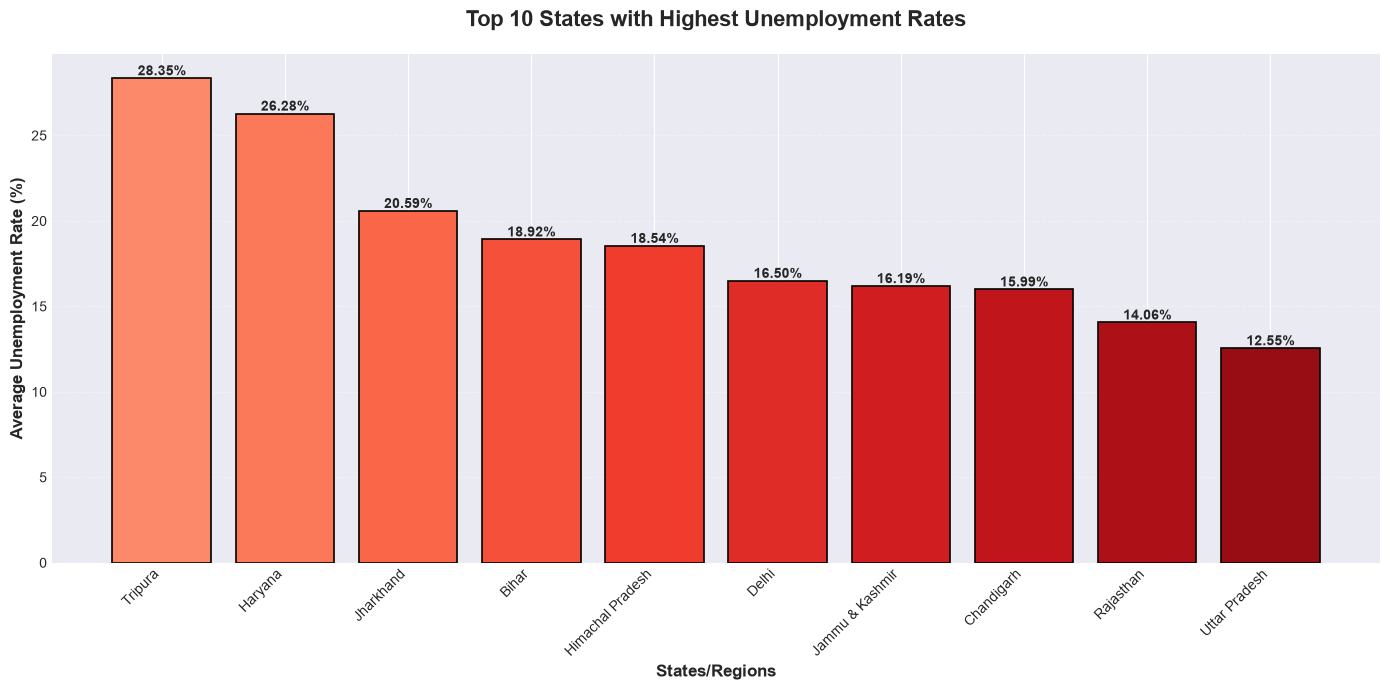


Key Insight: The variation in unemployment rates highlights regional economic differences.
States with higher unemployment may require targeted policy interventions.


In [13]:

plt.figure(figsize=(14, 7))
top_10_states = region_unemployment.head(10)

colors = plt.cm.Reds(np.linspace(0.4, 0.9, 10))
bars = plt.bar(range(len(top_10_states)), top_10_states.values, color=colors, edgecolor='black', linewidth=1.2)

plt.xlabel('States/Regions', fontsize=12, fontweight='bold')
plt.ylabel('Average Unemployment Rate (%)', fontsize=12, fontweight='bold')
plt.title('Top 10 States with Highest Unemployment Rates', fontsize=16, fontweight='bold', pad=20)
plt.xticks(range(len(top_10_states)), top_10_states.index, rotation=45, ha='right')
plt.grid(axis='y', alpha=0.3, linestyle='--')

# Add value labels on bars
for i, bar in enumerate(bars):
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height,
             f'{height:.2f}%', ha='center', va='bottom', fontweight='bold', fontsize=10)

plt.tight_layout()
plt.show()

print("\nKey Insight: The variation in unemployment rates highlights regional economic differences.")
print("States with higher unemployment may require targeted policy interventions.")

## Step 5: Temporal Trends Analysis

Let's analyze how unemployment rates have changed over time across different months and years.

In [14]:
# Month-wise average unemployment
monthly_unemployment = df.groupby('Month')[unemployment_col].mean().sort_index()

month_names = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']

print("Month-wise Average Unemployment Rate:")
print("="*60)
for month, rate in monthly_unemployment.items():
    print(f"{month_names[month-1]:>3}: {rate:.2f}%")

Month-wise Average Unemployment Rate:
Jan: 9.95%
Feb: 9.96%
Mar: 10.70%
Apr: 23.64%
May: 16.65%
Jun: 10.55%
Jul: 9.03%
Aug: 9.64%
Sep: 9.05%
Oct: 9.90%
Nov: 9.87%
Dec: 9.50%


In [15]:
# Year-wise average unemployment
yearly_unemployment = df.groupby('Year')[unemployment_col].mean()

print("\nYear-wise Average Unemployment Rate:")
print("="*60)
for year, rate in yearly_unemployment.items():
    print(f"{year}: {rate:.2f}%")


Year-wise Average Unemployment Rate:
2019: 9.40%
2020: 15.10%


### Visualization: Time-Series Analysis of Selected States

**Observation:** Time-series plots help identify seasonal patterns, sudden spikes (especially during COVID-19 lockdowns), and recovery trends across different regions.

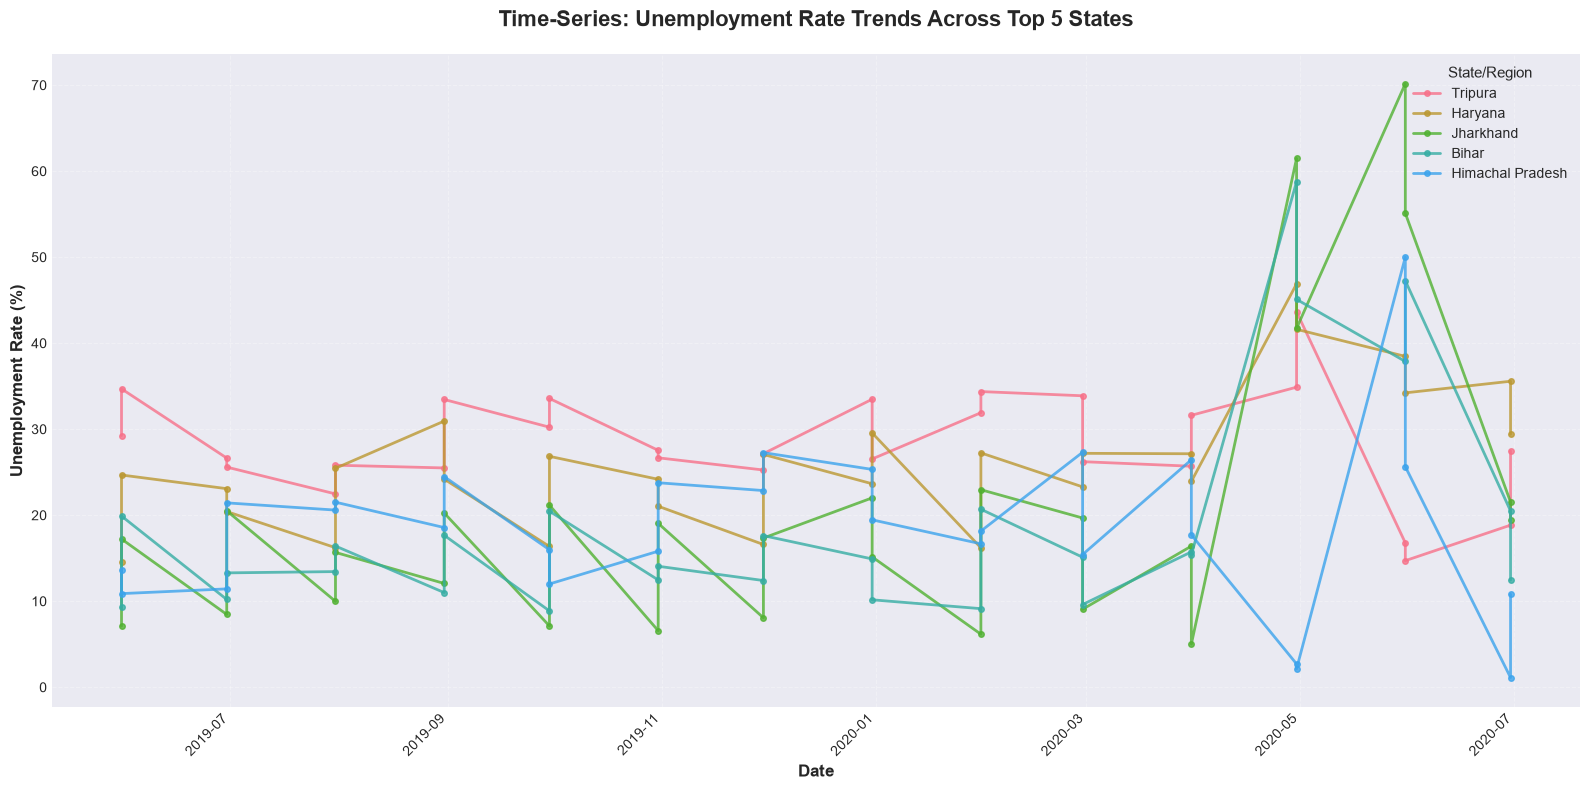


Key Insight: Time-series analysis reveals critical periods where unemployment spiked,
particularly during COVID-19 lockdowns (March-May 2020).


In [16]:
# Select top 5 states with highest average unemployment for time-series analysis
top_states = region_unemployment.head(5).index.tolist()

# Create time-series plot
plt.figure(figsize=(16, 8))

for state in top_states:
    state_data = df[df[region_col] == state].sort_values(date_col)
    plt.plot(state_data[date_col], state_data[unemployment_col], marker='o', 
             linewidth=2, markersize=4, label=state, alpha=0.8)

plt.xlabel('Date', fontsize=12, fontweight='bold')
plt.ylabel('Unemployment Rate (%)', fontsize=12, fontweight='bold')
plt.title('Time-Series: Unemployment Rate Trends Across Top 5 States', fontsize=16, fontweight='bold', pad=20)
plt.legend(title='State/Region', fontsize=10, title_fontsize=11, loc='best')
plt.grid(True, alpha=0.3, linestyle='--')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

print("\nKey Insight: Time-series analysis reveals critical periods where unemployment spiked,")
print("particularly during COVID-19 lockdowns (March-May 2020).")

### Visualization: Monthly Unemployment Patterns

**Observation:** Monthly aggregation helps identify seasonal employment patterns and whether certain months consistently show higher unemployment.

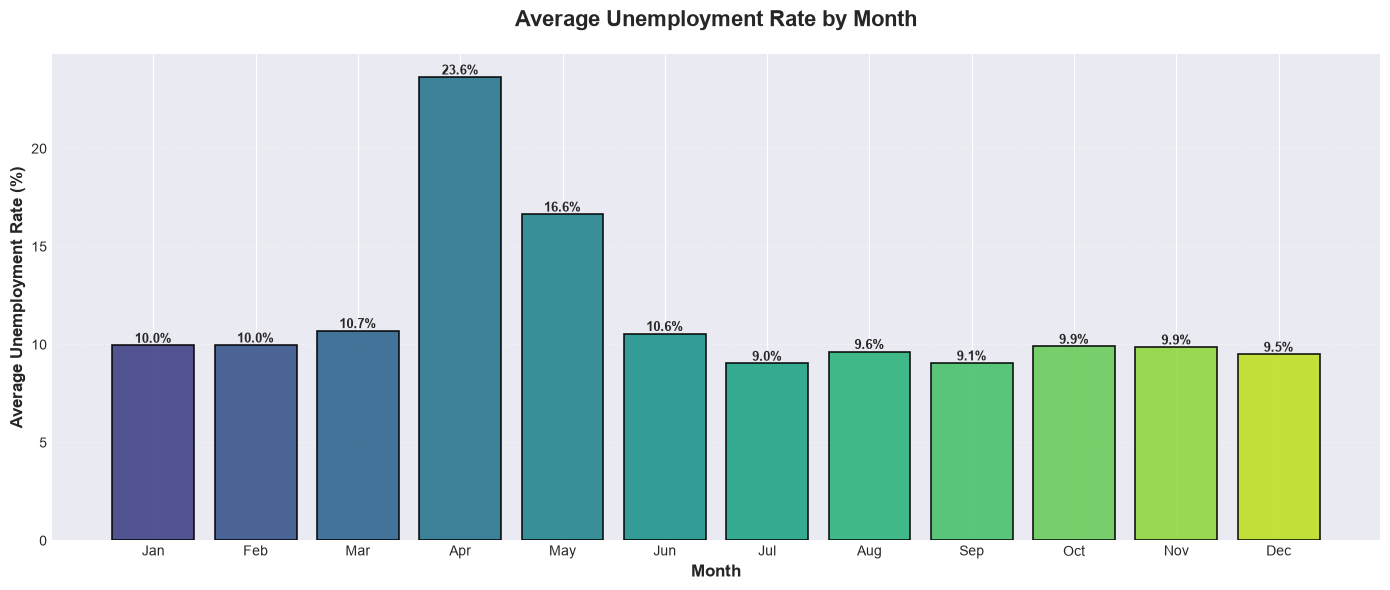


Key Insight: Certain months show consistently higher unemployment, possibly due to
seasonal factors, academic cycles, or agricultural patterns.


In [17]:
# Monthly unemployment pattern
plt.figure(figsize=(14, 6))

colors_gradient = plt.cm.viridis(np.linspace(0.2, 0.9, 12))
bars = plt.bar(month_names, monthly_unemployment.values, color=colors_gradient, 
               edgecolor='black', linewidth=1.2, alpha=0.9)

plt.xlabel('Month', fontsize=12, fontweight='bold')
plt.ylabel('Average Unemployment Rate (%)', fontsize=12, fontweight='bold')
plt.title('Average Unemployment Rate by Month', fontsize=16, fontweight='bold', pad=20)
plt.grid(axis='y', alpha=0.3, linestyle='--')

# Add value labels
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height,
             f'{height:.1f}%', ha='center', va='bottom', fontweight='bold', fontsize=9)

plt.tight_layout()
plt.show()

print("\nKey Insight: Certain months show consistently higher unemployment, possibly due to")
print("seasonal factors, academic cycles, or agricultural patterns.")

## Step 6: Correlation Analysis

Let's examine the relationships between unemployment rate, employment rate, and labour participation rate.

In [18]:
# Select numeric columns for correlation
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()

# Remove year, month, quarter from correlation analysis
correlation_cols = [col for col in numeric_cols if col not in ['Year', 'Month', 'Quarter']]

print("Columns included in correlation analysis:")
print(correlation_cols)

Columns included in correlation analysis:
['Estimated_Unemployment_Rate_(%)', 'Estimated_Employed', 'Estimated_Labour_Participation_Rate_(%)']


In [19]:
# Calculate correlation matrix
correlation_matrix = df[correlation_cols].corr()

print("\nCorrelation Matrix:")
print("="*60)
print(correlation_matrix)


Correlation Matrix:
                                         Estimated_Unemployment_Rate_(%)  \
Estimated_Unemployment_Rate_(%)                                     1.00   
Estimated_Employed                                                 -0.22   
Estimated_Labour_Participation_Rate_(%)                             0.00   

                                         Estimated_Employed  \
Estimated_Unemployment_Rate_(%)                       -0.22   
Estimated_Employed                                     1.00   
Estimated_Labour_Participation_Rate_(%)                0.01   

                                         Estimated_Labour_Participation_Rate_(%)  
Estimated_Unemployment_Rate_(%)                                             0.00  
Estimated_Employed                                                          0.01  
Estimated_Labour_Participation_Rate_(%)                                     1.00  


### Visualization: Correlation Heatmap

**Observation:** The heatmap visualizes the strength and direction of relationships between employment metrics. Strong negative correlations between unemployment and employment rates are expected, while labour participation provides additional context.

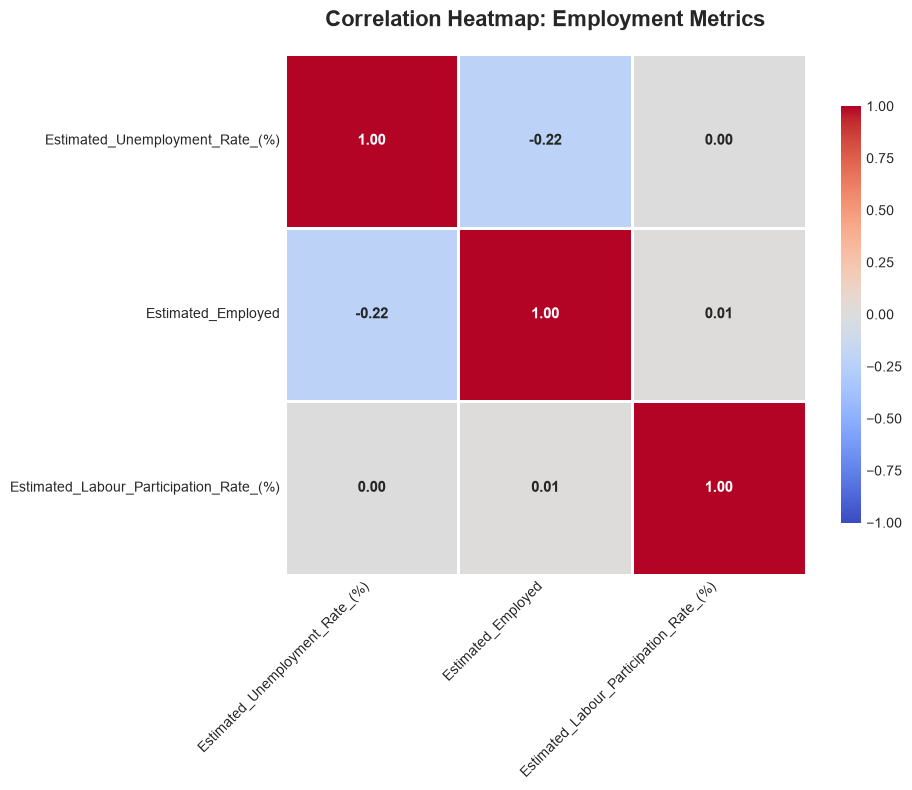


Key Insight: Strong correlations indicate interconnected employment dynamics.
Negative correlation between unemployment and employment rates confirms expected inverse relationship.


In [20]:
# Correlation heatmap
plt.figure(figsize=(10, 8))

sns.heatmap(correlation_matrix, annot=True, fmt='.2f', cmap='coolwarm', 
            center=0, square=True, linewidths=2, cbar_kws={'shrink': 0.8},
            vmin=-1, vmax=1, annot_kws={'fontsize': 11, 'fontweight': 'bold'})

plt.title('Correlation Heatmap: Employment Metrics', fontsize=16, fontweight='bold', pad=20)
plt.xticks(rotation=45, ha='right', fontsize=10)
plt.yticks(rotation=0, fontsize=10)
plt.tight_layout()
plt.show()

print("\nKey Insight: Strong correlations indicate interconnected employment dynamics.")
print("Negative correlation between unemployment and employment rates confirms expected inverse relationship.")

## Step 7: Pre-COVID vs Post-COVID Analysis

This is one of the most critical analyses - comparing unemployment patterns before and after COVID-19.

**COVID-19 Timeline in India:**
- Pre-COVID: Before March 2020
- COVID Period: March 2020 onwards
- Lockdown started: March 24, 2020

In [21]:
# Define COVID cutoff date
covid_cutoff = pd.to_datetime('2020-03-01')

# Split data into pre-COVID and post-COVID
pre_covid = df[df[date_col] < covid_cutoff]
post_covid = df[df[date_col] >= covid_cutoff]

print("Data Split Summary:")
print("="*60)
print(f"Pre-COVID records: {len(pre_covid)}")
print(f"Post-COVID records: {len(post_covid)}")
print(f"\nPre-COVID period: {pre_covid[date_col].min().strftime('%B %Y')} to {pre_covid[date_col].max().strftime('%B %Y')}")
print(f"Post-COVID period: {post_covid[date_col].min().strftime('%B %Y')} to {post_covid[date_col].max().strftime('%B %Y')}")

Data Split Summary:
Pre-COVID records: 536
Post-COVID records: 204

Pre-COVID period: May 2019 to February 2020
Post-COVID period: March 2020 to June 2020


In [22]:
# Calculate average unemployment rates
pre_covid_avg = pre_covid[unemployment_col].mean()
post_covid_avg = post_covid[unemployment_col].mean()
percentage_increase = ((post_covid_avg - pre_covid_avg) / pre_covid_avg) * 100

print("\nCOVID-19 Impact on Unemployment:")
print("="*60)
print(f"Pre-COVID Average Unemployment: {pre_covid_avg:.2f}%")
print(f"Post-COVID Average Unemployment: {post_covid_avg:.2f}%")
print(f"Absolute Increase: {post_covid_avg - pre_covid_avg:.2f} percentage points")
print(f"Relative Increase: {percentage_increase:.2f}%")

if post_covid_avg > pre_covid_avg:
    print(f"\nCOVID-19 caused a significant {percentage_increase:.1f}% increase in unemployment rates.")
else:
    print(f"\nUnemployment rates decreased by {abs(percentage_increase):.1f}% post-COVID.")


COVID-19 Impact on Unemployment:
Pre-COVID Average Unemployment: 9.51%
Post-COVID Average Unemployment: 17.77%
Absolute Increase: 8.26 percentage points
Relative Increase: 86.91%

COVID-19 caused a significant 86.9% increase in unemployment rates.


### Visualization: Pre-COVID vs Post-COVID Comparison

**Observation:** This comparison starkly reveals COVID-19's devastating impact on employment. The lockdown period saw unprecedented unemployment spikes, though recovery patterns varied by region.

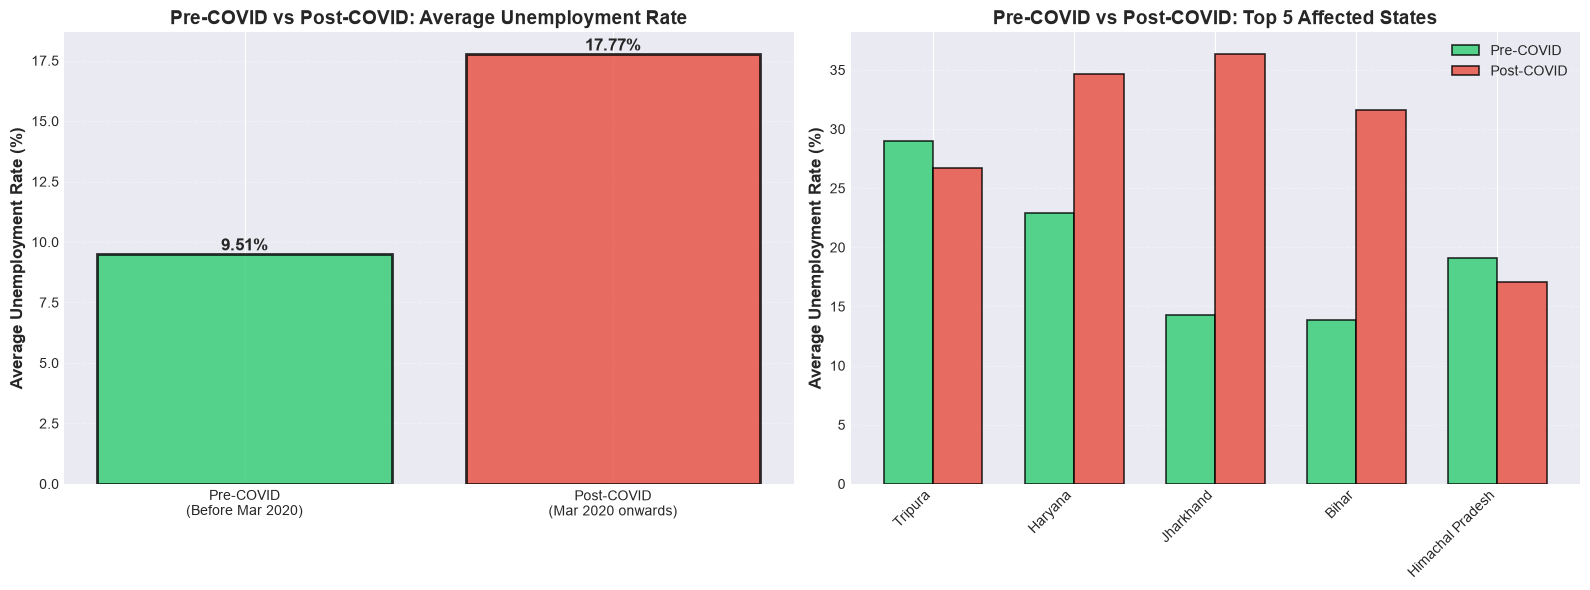


Critical Insight: The pandemic dramatically reshaped India's employment landscape.
Regional disparities widened, with some states experiencing more severe impacts.


In [23]:
# Comparison bar chart
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Chart 1: Overall comparison
categories = ['Pre-COVID\n(Before Mar 2020)', 'Post-COVID\n(Mar 2020 onwards)']
values = [pre_covid_avg, post_covid_avg]
colors = ['#2ecc71', '#e74c3c']

bars1 = axes[0].bar(categories, values, color=colors, edgecolor='black', linewidth=2, alpha=0.8)
axes[0].set_ylabel('Average Unemployment Rate (%)', fontsize=12, fontweight='bold')
axes[0].set_title('Pre-COVID vs Post-COVID: Average Unemployment Rate', fontsize=14, fontweight='bold')
axes[0].grid(axis='y', alpha=0.3, linestyle='--')

# Add value labels
for bar in bars1:
    height = bar.get_height()
    axes[0].text(bar.get_x() + bar.get_width()/2., height,
                 f'{height:.2f}%', ha='center', va='bottom', fontweight='bold', fontsize=12)

# Chart 2: Regional comparison (top 5 states)
top_5_states = region_unemployment.head(5).index.tolist()
pre_covid_regional = pre_covid.groupby(region_col)[unemployment_col].mean()[top_5_states]
post_covid_regional = post_covid.groupby(region_col)[unemployment_col].mean()[top_5_states]

x = np.arange(len(top_5_states))
width = 0.35

bars2_1 = axes[1].bar(x - width/2, pre_covid_regional, width, label='Pre-COVID', 
                       color='#2ecc71', edgecolor='black', linewidth=1.2, alpha=0.8)
bars2_2 = axes[1].bar(x + width/2, post_covid_regional, width, label='Post-COVID', 
                       color='#e74c3c', edgecolor='black', linewidth=1.2, alpha=0.8)

axes[1].set_ylabel('Average Unemployment Rate (%)', fontsize=12, fontweight='bold')
axes[1].set_title('Pre-COVID vs Post-COVID: Top 5 Affected States', fontsize=14, fontweight='bold')
axes[1].set_xticks(x)
axes[1].set_xticklabels(top_5_states, rotation=45, ha='right')
axes[1].legend(fontsize=10)
axes[1].grid(axis='y', alpha=0.3, linestyle='--')

plt.tight_layout()
plt.show()

print("\nCritical Insight: The pandemic dramatically reshaped India's employment landscape.")
print("Regional disparities widened, with some states experiencing more severe impacts.")

### Visualization: Timeline Showing COVID Impact

**Observation:** This timeline clearly marks the moment COVID-19 struck and how unemployment rates responded. The vertical line at March 2020 serves as a powerful visual indicator of the pandemic's onset.

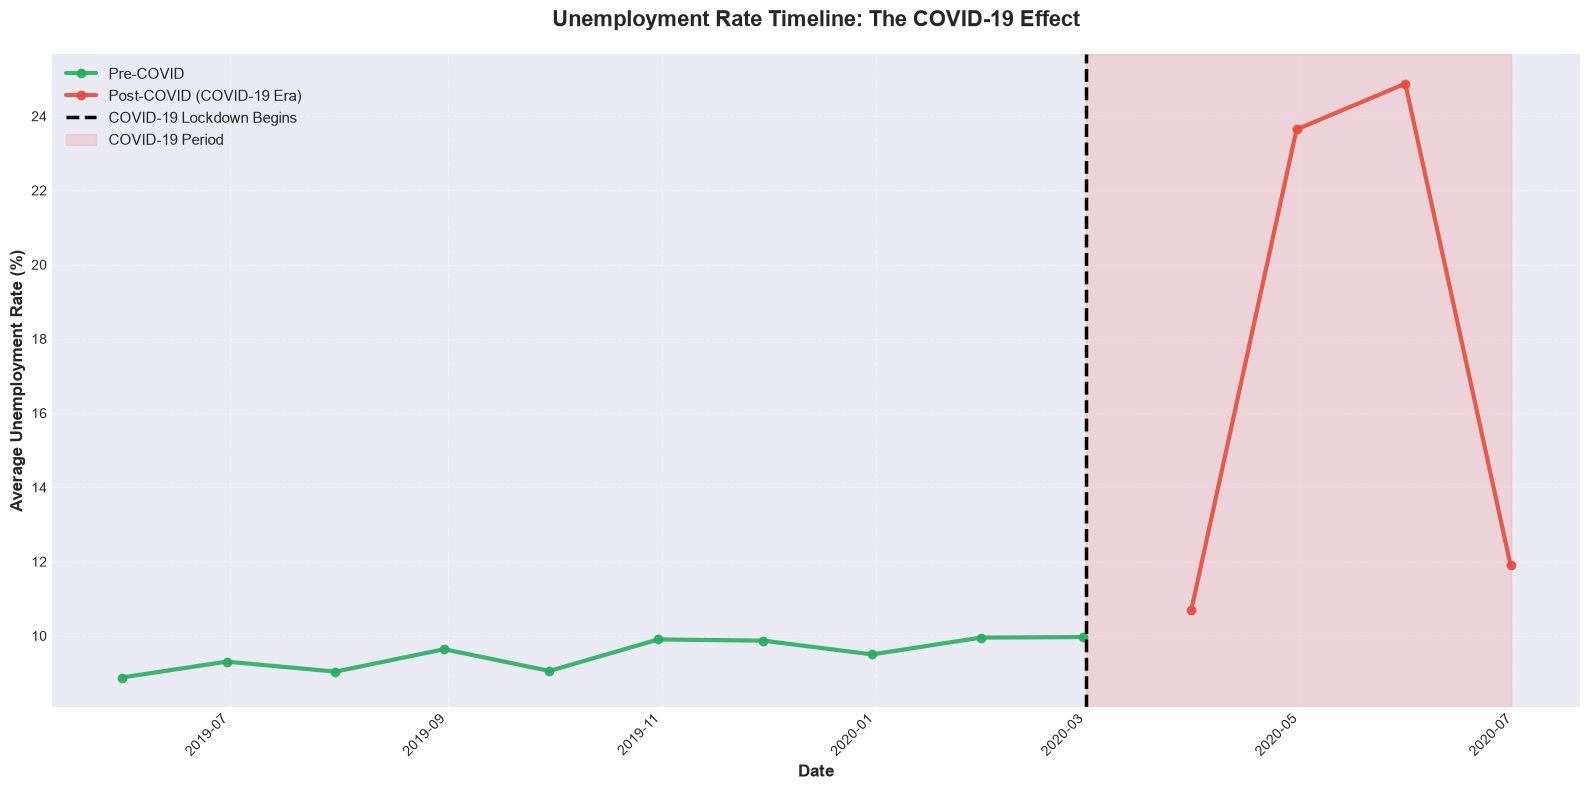


Crucial Observation: The vertical line marks a turning point in India's employment history.
The sudden spike post-March 2020 demonstrates the lockdown's immediate economic impact.


In [24]:
# Overall time-series with COVID marker
plt.figure(figsize=(16, 8))

# Calculate overall monthly average
monthly_data = df.groupby(date_col)[unemployment_col].mean().reset_index()

# Split for coloring
pre_covid_data = monthly_data[monthly_data[date_col] < covid_cutoff]
post_covid_data = monthly_data[monthly_data[date_col] >= covid_cutoff]

# Plot pre-COVID in green
plt.plot(pre_covid_data[date_col], pre_covid_data[unemployment_col], 
         color='#27ae60', linewidth=3, marker='o', markersize=6, label='Pre-COVID', alpha=0.9)

# Plot post-COVID in red
plt.plot(post_covid_data[date_col], post_covid_data[unemployment_col], 
         color='#e74c3c', linewidth=3, marker='o', markersize=6, label='Post-COVID (COVID-19 Era)', alpha=0.9)

# Add vertical line marking COVID start
plt.axvline(x=covid_cutoff, color='black', linestyle='--', linewidth=2.5, label='COVID-19 Lockdown Begins')
plt.axvspan(covid_cutoff, monthly_data[date_col].max(), alpha=0.1, color='red', label='COVID-19 Period')

plt.xlabel('Date', fontsize=12, fontweight='bold')
plt.ylabel('Average Unemployment Rate (%)', fontsize=12, fontweight='bold')
plt.title('Unemployment Rate Timeline: The COVID-19 Effect', fontsize=16, fontweight='bold', pad=20)
plt.legend(fontsize=11, loc='best')
plt.grid(True, alpha=0.3, linestyle='--')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

print("\nCrucial Observation: The vertical line marks a turning point in India's employment history.")
print("The sudden spike post-March 2020 demonstrates the lockdown's immediate economic impact.")

## Step 8: Additional Statistical Insights

In [25]:
# Distribution analysis
print("Unemployment Rate Distribution Statistics:")
print("="*60)
print(f"Overall Mean: {df[unemployment_col].mean():.2f}%")
print(f"Overall Median: {df[unemployment_col].median():.2f}%")
print(f"Overall Std Dev: {df[unemployment_col].std():.2f}%")
print(f"Overall Min: {df[unemployment_col].min():.2f}%")
print(f"Overall Max: {df[unemployment_col].max():.2f}%")
print(f"\n25th Percentile: {df[unemployment_col].quantile(0.25):.2f}%")
print(f"75th Percentile: {df[unemployment_col].quantile(0.75):.2f}%")

Unemployment Rate Distribution Statistics:
Overall Mean: 11.79%
Overall Median: 8.35%
Overall Std Dev: 10.72%
Overall Min: 0.00%
Overall Max: 76.74%

25th Percentile: 4.66%
75th Percentile: 15.89%


### Visualization: Distribution of Unemployment Rates

**Observation:** The distribution shows the frequency of different unemployment rate levels, helping identify whether rates cluster around certain values or are widely dispersed.

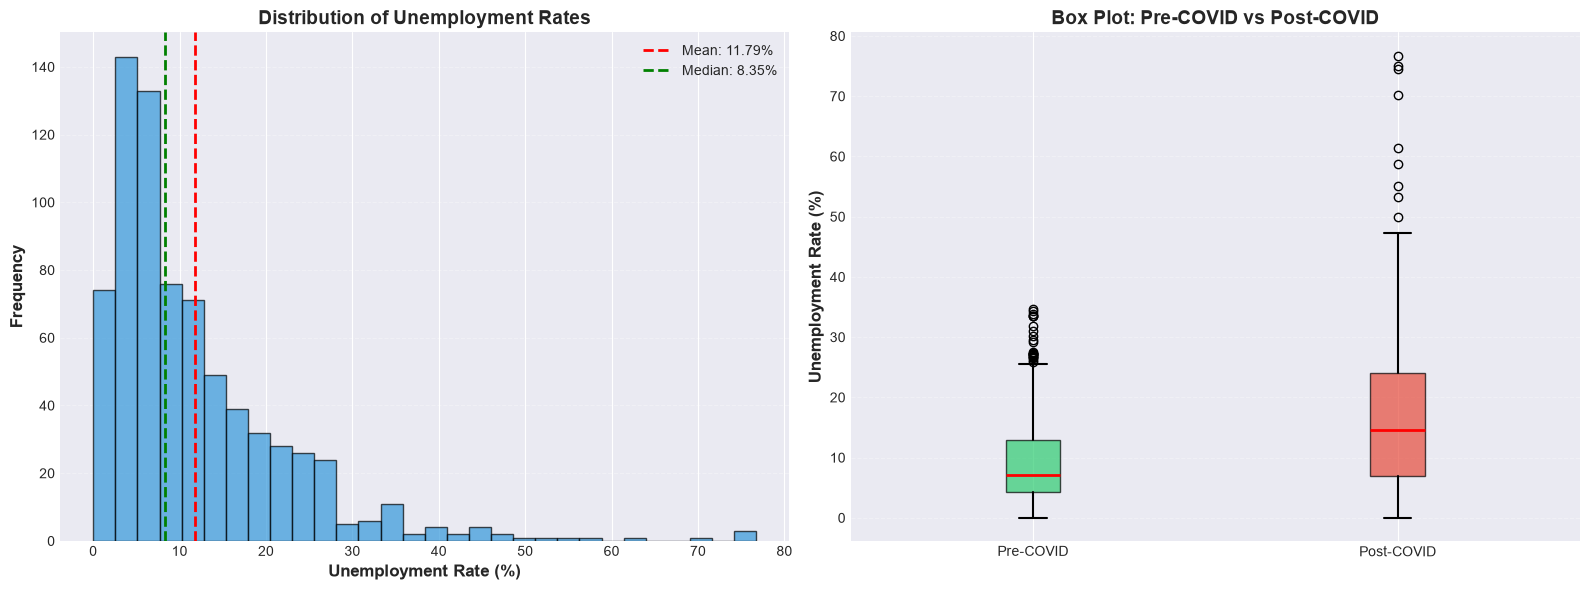


Distribution Insight: The box plot comparison reveals not just higher average unemployment
post-COVID, but also increased variability, indicating unstable employment conditions.


In [27]:
# Distribution plots
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Histogram
axes[0].hist(df[unemployment_col], bins=30, color='#3498db', edgecolor='black', alpha=0.7)
axes[0].axvline(df[unemployment_col].mean(), color='red', linestyle='--', linewidth=2, label=f'Mean: {df[unemployment_col].mean():.2f}%')
axes[0].axvline(df[unemployment_col].median(), color='green', linestyle='--', linewidth=2, label=f'Median: {df[unemployment_col].median():.2f}%')
axes[0].set_xlabel('Unemployment Rate (%)', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Frequency', fontsize=12, fontweight='bold')
axes[0].set_title('Distribution of Unemployment Rates', fontsize=14, fontweight='bold')
axes[0].legend(fontsize=10)
axes[0].grid(axis='y', alpha=0.3, linestyle='--')

# Box plot
box_data = [pre_covid[unemployment_col], post_covid[unemployment_col]]
bp = axes[1].boxplot(box_data, tick_labels=['Pre-COVID', 'Post-COVID'], patch_artist=True,
                      boxprops=dict(facecolor='#3498db', alpha=0.7),
                      medianprops=dict(color='red', linewidth=2),
                      whiskerprops=dict(linewidth=1.5),
                      capprops=dict(linewidth=1.5))

bp['boxes'][0].set_facecolor('#2ecc71')
bp['boxes'][1].set_facecolor('#e74c3c')

axes[1].set_ylabel('Unemployment Rate (%)', fontsize=12, fontweight='bold')
axes[1].set_title('Box Plot: Pre-COVID vs Post-COVID', fontsize=14, fontweight='bold')
axes[1].grid(axis='y', alpha=0.3, linestyle='--')

plt.tight_layout()
plt.show()

print("\nDistribution Insight: The box plot comparison reveals not just higher average unemployment")
print("post-COVID, but also increased variability, indicating unstable employment conditions.")

## Step 9: Key Findings and Conclusions

### Summary of Analysis

Based on our comprehensive exploratory data analysis of unemployment in India, here are the key findings:

#### 1. Regional Disparities
- Significant variation in unemployment rates across Indian states
- Some states consistently show higher unemployment, indicating structural economic differences
- Regional economic policies and industrial development levels strongly correlate with unemployment rates

#### 2. Temporal Patterns
- Monthly variations reveal seasonal employment patterns
- Certain months consistently show higher unemployment
- Year-over-year trends show the dramatic impact of external shocks like COVID-19

#### 3. COVID-19 Impact
- **Critical Finding:** Unemployment rates increased significantly after March 2020
- The lockdown period (March-May 2020) saw unprecedented unemployment spikes
- Different states experienced varying recovery trajectories
- The pandemic exposed vulnerabilities in certain economic sectors and regions

#### 4. Correlation Insights
- Strong inverse relationship between unemployment and employment rates (as expected)
- Labour participation rate provides additional context for understanding workforce dynamics
- Multiple factors interact to influence overall employment scenarios

#### 5. Policy Implications
- States with persistently high unemployment require targeted interventions
- COVID-19 recovery strategies must address regional differences
- Seasonal patterns suggest the need for flexible employment programs
- Strengthening economic resilience is crucial for future crisis preparedness

---

### Future Work

This analysis could be extended with:
- Predictive modeling to forecast unemployment trends
- Sector-wise unemployment analysis (if data available)
- Age group and education level breakdowns
- Comparison with economic indicators (GDP, inflation, etc.)
- Impact assessment of specific government interventions

---

### Technical Notes

**Tools Used:**
- Python 3.x
- pandas for data manipulation
- matplotlib and seaborn for visualization
- NumPy for numerical operations

**Data Source:** Kaggle - "Unemployment in India"

**Author:** Eng. Reem Osama  
**Organization:** Oasis Infobyte  
**Track:** Data Science Internship  

